# Lab 2: Image Synthesis Using GANs

**Course:** ETMMGA304 - Generative AI and Its Applications (MCA)

**Name:** Anuj

**Roll No.:** 2501940039

**Program:** MCA (AI & ML)

**Aim:** To train a basic Generative Adversarial Network (GAN) on the Fashion-MNIST dataset and evaluate the generated images using fixed-noise sample grids and loss curves.

## Import **libraries**

In [1]:
from pathlib import Path
import random
import torch
import matplotlib.pyplot as plt

# Set random seed for reproducibility
SEED = 42

random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Select GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create output directory
out = Path("lab_outputs")
out.mkdir(exist_ok=True)

print("Device:", device)
print("PyTorch Version:", torch.__version__)

Device: cuda
PyTorch Version: 2.14.1+cu130


## Load and preprocess Fashion-MNIST **dataset**

In [2]:
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

# Normalize images to the range [-1, 1]
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Download Fashion-MNIST training dataset
data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)

# Create DataLoader
loader = DataLoader(
    data,
    batch_size=128,
    shuffle=True
)

print("Total training images:", len(data))
print("Batch size:", loader.batch_size)
print("Total batches:", len(loader))

# Display one batch
images, labels = next(iter(loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Minimum pixel value:", images.min().item())
print("Maximum pixel value:", images.max().item())

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.75MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 23.8MB/s]

Total training images: 60000
Batch size: 128
Total batches: 469
Image batch shape: torch.Size([128, 1, 28, 28])
Label batch shape: torch.Size([128])
Minimum pixel value: -1.0
Maximum pixel value: 1.0


## **Display sample Fashion-MNIST images**

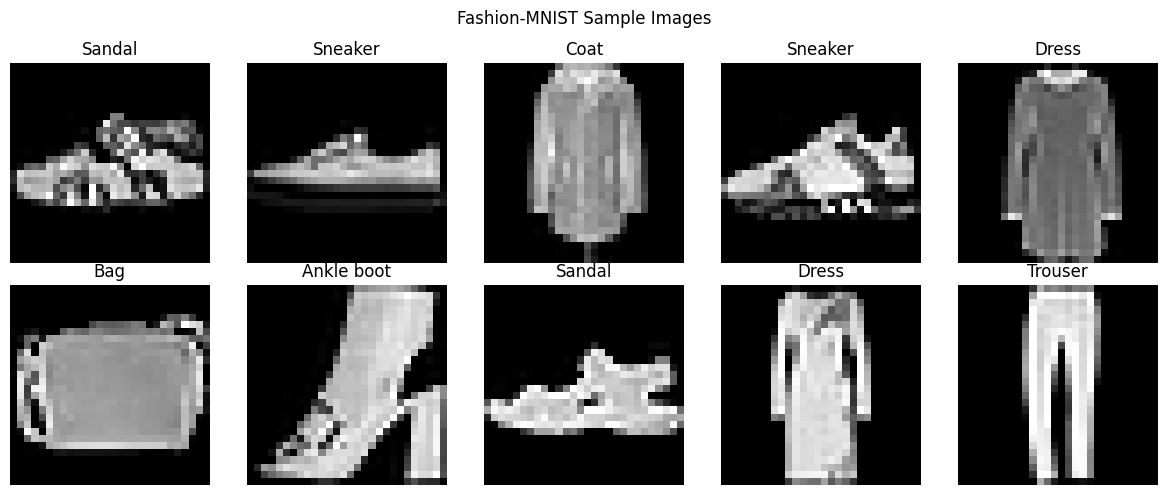

In [3]:
classes = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(classes[labels[i].item()])
    ax.axis("off")

plt.suptitle("Fashion-MNIST Sample Images")
plt.tight_layout()
plt.show()

## **Define Generator and Discriminator bold text**

In [4]:
# Latent noise dimension
latent_dim = 64

# Generator Network
G = nn.Sequential(
    nn.Linear(latent_dim, 256),
    nn.LeakyReLU(0.2),

    nn.Linear(256, 512),
    nn.LeakyReLU(0.2),

    nn.Linear(512, 784),
    nn.Tanh()
).to(device)


# Discriminator Network
D = nn.Sequential(
    nn.Flatten(),

    nn.Linear(784, 512),
    nn.LeakyReLU(0.2),

    nn.Linear(512, 256),
    nn.LeakyReLU(0.2),

    nn.Linear(256, 1)
).to(device)


# Binary Cross Entropy Loss
loss_fn = nn.BCEWithLogitsLoss()

# Adam optimizers
opt_g = torch.optim.Adam(
    G.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

opt_d = torch.optim.Adam(
    D.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

# Fixed noise for image generation
fixed_z = torch.randn(25, latent_dim, device=device)

print("Generator Architecture:")
print(G)

print("\nDiscriminator Architecture:")
print(D)

Generator Architecture:
Sequential(
  (0): Linear(in_features=64, out_features=256, bias=True)
  (1): LeakyReLU(negative_slope=0.2)
  (2): Linear(in_features=256, out_features=512, bias=True)
  (3): LeakyReLU(negative_slope=0.2)
  (4): Linear(in_features=512, out_features=784, bias=True)
  (5): Tanh()
)

Discriminator Architecture:
Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=512, bias=True)
  (2): LeakyReLU(negative_slope=0.2)
  (3): Linear(in_features=512, out_features=256, bias=True)
  (4): LeakyReLU(negative_slope=0.2)
  (5): Linear(in_features=256, out_features=1, bias=True)
)


## **network output shapes**

In [5]:
# Generate a batch of 8 random noise vectors
z = torch.randn(8, latent_dim, device=device)

# Generate fake images
generated_images = G(z)

# Discriminator predictions
predictions = D(generated_images)

print("Noise Input Shape:", z.shape)
print("Generator Output Shape:", generated_images.shape)
print("Generator Minimum Value:", generated_images.min().item())
print("Generator Maximum Value:", generated_images.max().item())
print("Discriminator Output Shape:", predictions.shape)

Noise Input Shape: torch.Size([8, 64])
Generator Output Shape: torch.Size([8, 784])
Generator Minimum Value: -0.410707950592041
Generator Maximum Value: 0.35144466161727905
Discriminator Output Shape: torch.Size([8, 1])


## **Function to generate image grids**

In [6]:
def generate_grid(epoch):

    G.eval()

    with torch.no_grad():
        images = G(fixed_z).cpu().reshape(-1, 1, 28, 28)

        # Convert pixel values from [-1, 1] to [0, 1]
        grid = make_grid(
            (images + 1) / 2,
            nrow=5
        )

    plt.figure(figsize=(6, 6))
    plt.imshow(grid.permute(1, 2, 0))
    plt.title(f"Generated Fashion Images - Epoch {epoch}")
    plt.axis("off")

    # Save generated grid
    plt.savefig(
        out / f"gan_epoch_{epoch:02d}.png",
        bbox_inches="tight"
    )

    plt.show()

    G.train()

## **Define the alternating training function**

In [7]:
def train_batch(real):

    n = real.size(0)

    # Generate fake images
    fake = G(
        torch.randn(n, latent_dim, device=device)
    )

    # -------------------------------
    # Discriminator Training
    # -------------------------------

    real_logits = D(real)
    fake_logits = D(fake.detach())

    real_labels = torch.ones_like(real_logits)
    fake_labels = torch.zeros_like(fake_logits)

    d_loss = (
        loss_fn(real_logits, real_labels) +
        loss_fn(fake_logits, fake_labels)
    ) / 2

    opt_d.zero_grad()
    d_loss.backward()
    opt_d.step()

    # -------------------------------
    # Generator Training
    # -------------------------------

    D.requires_grad_(False)

    opt_g.zero_grad()

    logits = D(fake)

    # Generator wants fake images to be classified as real
    g_loss = loss_fn(
        logits,
        torch.ones_like(logits)
    )

    g_loss.backward()
    opt_g.step()

    D.requires_grad_(True)

    return d_loss.item(), g_loss.item()

## Train GAN for 10 **epochs**

Epoch 01 | Discriminator Loss: 0.3533 | Generator Loss: 1.8129


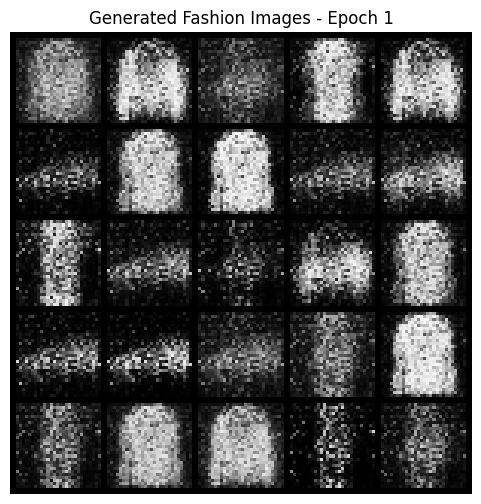

Epoch 02 | Discriminator Loss: 0.3155 | Generator Loss: 2.6379
Epoch 03 | Discriminator Loss: 0.4032 | Generator Loss: 2.1088
Epoch 04 | Discriminator Loss: 0.4016 | Generator Loss: 2.0767
Epoch 05 | Discriminator Loss: 0.4204 | Generator Loss: 1.9801


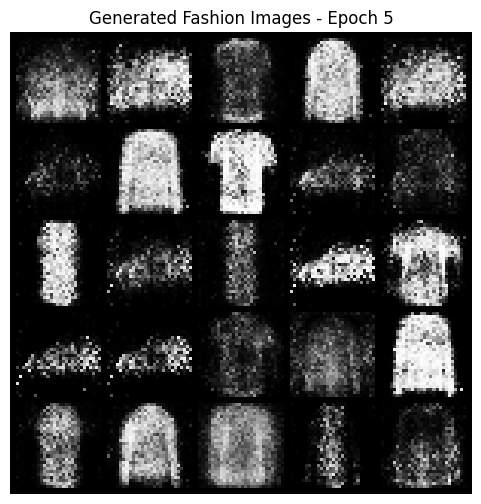

Epoch 06 | Discriminator Loss: 0.4313 | Generator Loss: 1.8676
Epoch 07 | Discriminator Loss: 0.4491 | Generator Loss: 1.8701
Epoch 08 | Discriminator Loss: 0.4638 | Generator Loss: 1.7972
Epoch 09 | Discriminator Loss: 0.4708 | Generator Loss: 1.7838
Epoch 10 | Discriminator Loss: 0.4689 | Generator Loss: 1.7399


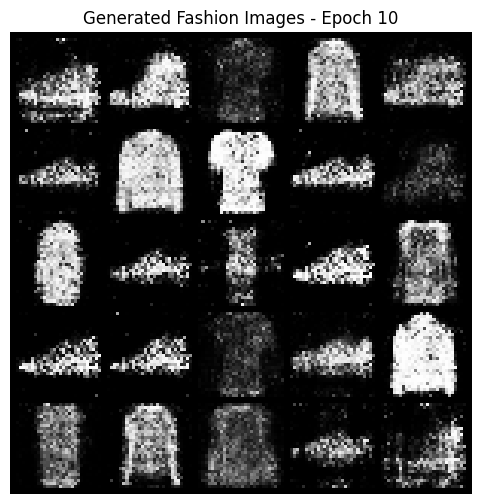


GAN Training Completed!


In [10]:
history = []

epochs = 10

for epoch in range(1, epochs + 1):

    losses = [
        train_batch(real.to(device))
        for real, _ in loader
    ]

    # Calculate average losses
    avg_d, avg_g = [
        sum(values) / len(losses)
        for values in zip(*losses)
    ]

    history.append((avg_d, avg_g))

    print(
        f"Epoch {epoch:02d} | "
        f"Discriminator Loss: {avg_d:.4f} | "
        f"Generator Loss: {avg_g:.4f}"
    )

    # Generate images at selected epochs
    if epoch in (1, 5, 10):
        generate_grid(epoch)

print("\nGAN Training Completed!")

## Plot Generator and Discriminator **losses**

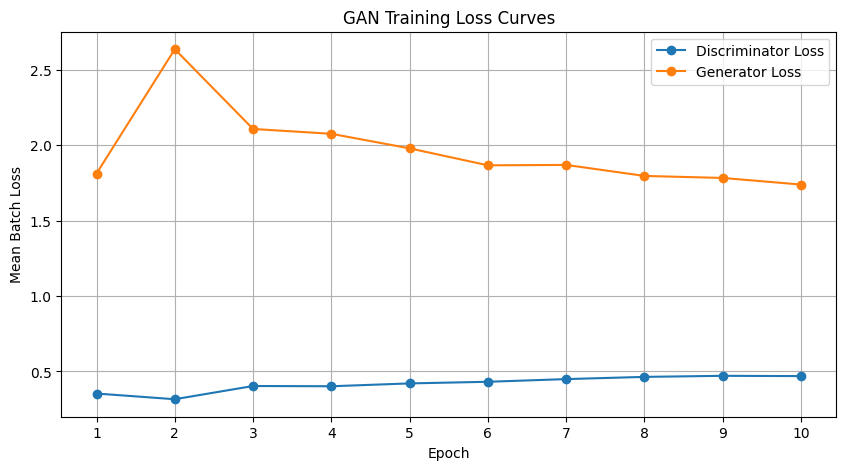

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 11),
    [d for d, g in history],
    marker="o",
    label="Discriminator Loss"
)

plt.plot(
    range(1, 11),
    [g for d, g in history],
    marker="o",
    label="Generator Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Batch Loss")
plt.title("GAN Training Loss Curves")

plt.xticks(range(1, 11))
plt.legend()
plt.grid(True)

plt.savefig(
    out / "gan_losses.png",
    bbox_inches="tight"
)

plt.show()

## Observation **table**

In [12]:
import pandas as pd

observations = []

for epoch in [1, 5, 10]:

    d_loss, g_loss = history[epoch - 1]

    observations.append({
        "Epoch": epoch,
        "Discriminator Loss": round(d_loss, 4),
        "Generator Loss": round(g_loss, 4)
    })

observation_df = pd.DataFrame(observations)

print("GAN Observation Table")
display(observation_df)

GAN Observation Table


,Epoch,Discriminator Loss,Generator Loss
0,1,0.3533,1.8129
1,5,0.4204,1.9801
2,10,0.4689,1.7399
